In [1]:
#### follow the notebook fro analysis of 1 subband effective model 

In [4]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
from Minimal_Model_2D import *
import Minimal_model_1D_1sub as M_1sub
import Minimal_Model_1D as M1
import time

np.set_printoptions(threshold=sys.maxsize)

In [5]:
NSM = 60          # in nm
MY = 4             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

print("MU =", MU_SC)

ALPHAT = np.linspace(1, 50, 81)

K = 8

Ep_li2 = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fli = M1.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li2[i,:] = Eli
    
    if i%5==0:
        print(i)


first subband energy = 1.3263440267269595 
 second subband energy = 2.652688053453919
first subband= 0.6631720133634798 second subband = 1.9895160400904393
MU = 1.4631720133634798
0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80


In [ ]:
np.save("1d_model_linear_SpinSplitting.npy", Ep_li2)

In [7]:
NSM = 60          # in nm
MY = 4             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

print("MU =", MU_SC)

ALPHAT = np.linspace(1, 50, 81)

K = 8

Ep_li = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fli = M_1sub.Model(N ,NSM, NSC, AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SM, MU_SM, phi=PHI)
    
    Hli = Fli.H_sys()

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li[i,:] = Eli
    
    if i%5==0:
        print(i)

np.save("1d_1subeff_model_linear_SpinSplitting.npy", Ep_li)

first subband energy = 1.3263440267269595 
 second subband energy = 2.652688053453919
first subband= 0.6631720133634798 second subband = 1.9895160400904393
MU = 1.4631720133634798
0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80


In [12]:
NSM = 60          # in nm
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

M = 100
AY = 5 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

print("MU =", MU_SC)

ALPHAT = np.linspace(1, 50, 81)

K = 8

Ep_li3 = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    ModCT = twoD_Minimal_Model(N, NSM, NSC, M, AX, AY, OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

    H = ModCT.H_sys(PHI, 'li')

    E = eigsh(H, k=K, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)

    Ep_li3[i,:] = Es

    #print(Es)

    #print(H.shape)

    if i % 5 == 0 :

        print(i)

np.save("2d_model_linear_SpinSplitting.npy", Ep_li3)

first subband energy = 1.3263440267269595 
 second subband energy = 2.652688053453919
first subband= 0.6631720133634798 second subband = 1.9895160400904393
MU = 1.4631720133634798
0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80


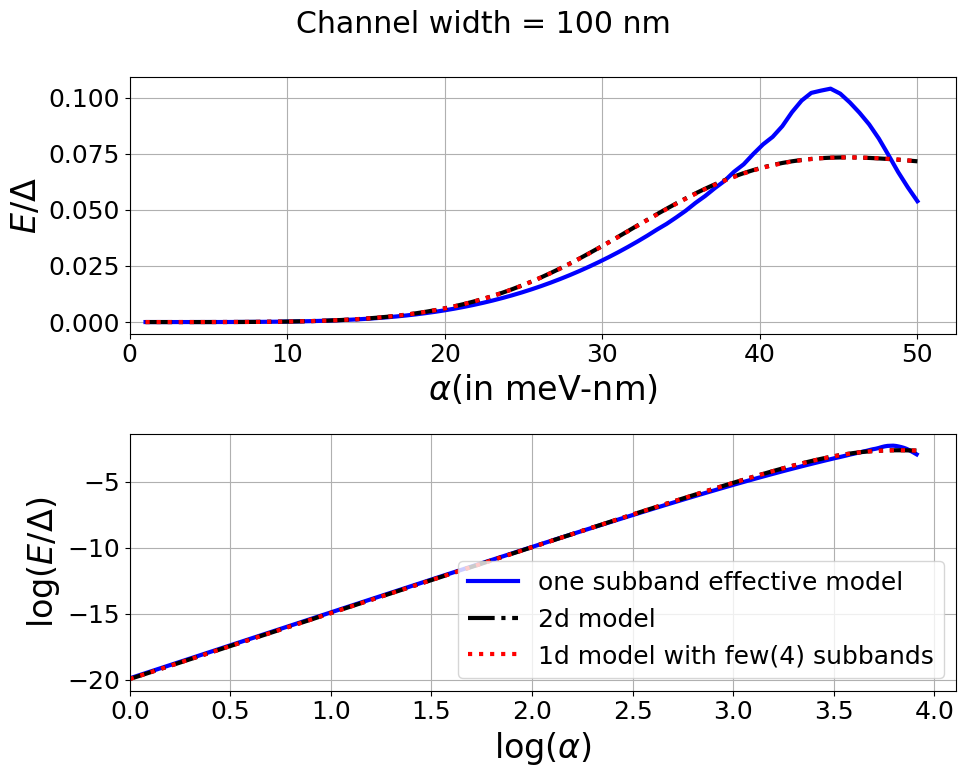

In [24]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li2 = (Ep_li2[:,K//2+1] - Ep_li2[:,K//2])
Ep_Split_li = (Ep_li[:,K//2+1] - Ep_li[:,K//2])
Ep_Split_li3 = (Ep_li3[:,K//2+1] - Ep_li3[:,K//2])


plt.subplot(2,1,1)
plt.plot((ALPHAT), (Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot((ALPHAT), (Ep_Split_li3/DELTA), lw=3 ,linestyle ='-.' , color='black', label= '2d model')
plt.plot((ALPHAT), (Ep_Split_li2/DELTA), lw=3 ,linestyle =':' , color='red', label= '1d model with few(4) subbands')

plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)

plt.subplot(2,1,2)
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li3/DELTA), lw=3 ,linestyle ='-.' , color='black', label=  '2d model')
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li2/DELTA), lw=3 ,linestyle =':' , color='red', label='1d model with few(4) subbands')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
plt.xlim(left=0)
plt.grid(True)

plt.suptitle('Channel width = %i nm' %LY)

plt.tight_layout()

plt.legend()

plt.show()

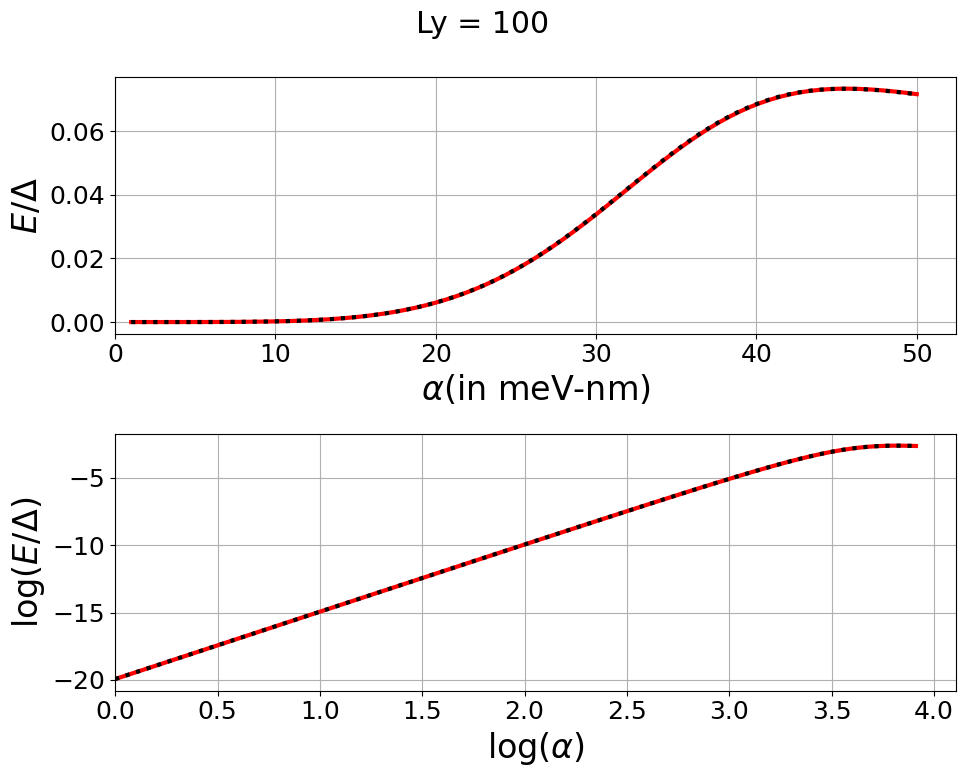

In [15]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li2 = (Ep_li2[:,K//2+1] - Ep_li2[:,K//2])
Ep_Split_li = (Ep_li[:,K//2+1] - Ep_li[:,K//2])
Ep_Split_li3 = (Ep_li3[:,K//2+1] - Ep_li3[:,K//2])


plt.subplot(2,1,1)
#plt.plot((ALPHAT), (Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.plot((ALPHAT), (Ep_Split_li2/DELTA), lw=3 ,linestyle ='-' , color='red')
plt.plot((ALPHAT), (Ep_Split_li3/DELTA), lw=3 ,linestyle =':' , color='black')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)

plt.subplot(2,1,2)
#plt.plot(np.log(ALPHAT), np.log(Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li2/DELTA), lw=3 ,linestyle ='-' , color='red')
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li3/DELTA), lw=3 ,linestyle =':' , color='black')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
plt.xlim(left=0)
plt.grid(True)

plt.suptitle('Ly = %i' %LY)

plt.tight_layout()

plt.show()